# Floorplan Order Matrix Demo

Structured SVG fixture for the indoor layout evaluation matrix. The notebook reads `floorplan_order_fixture.svg` through the automatic scene loader, runs `evaluate_scene(scene)`, and shows metric evidence overlays.

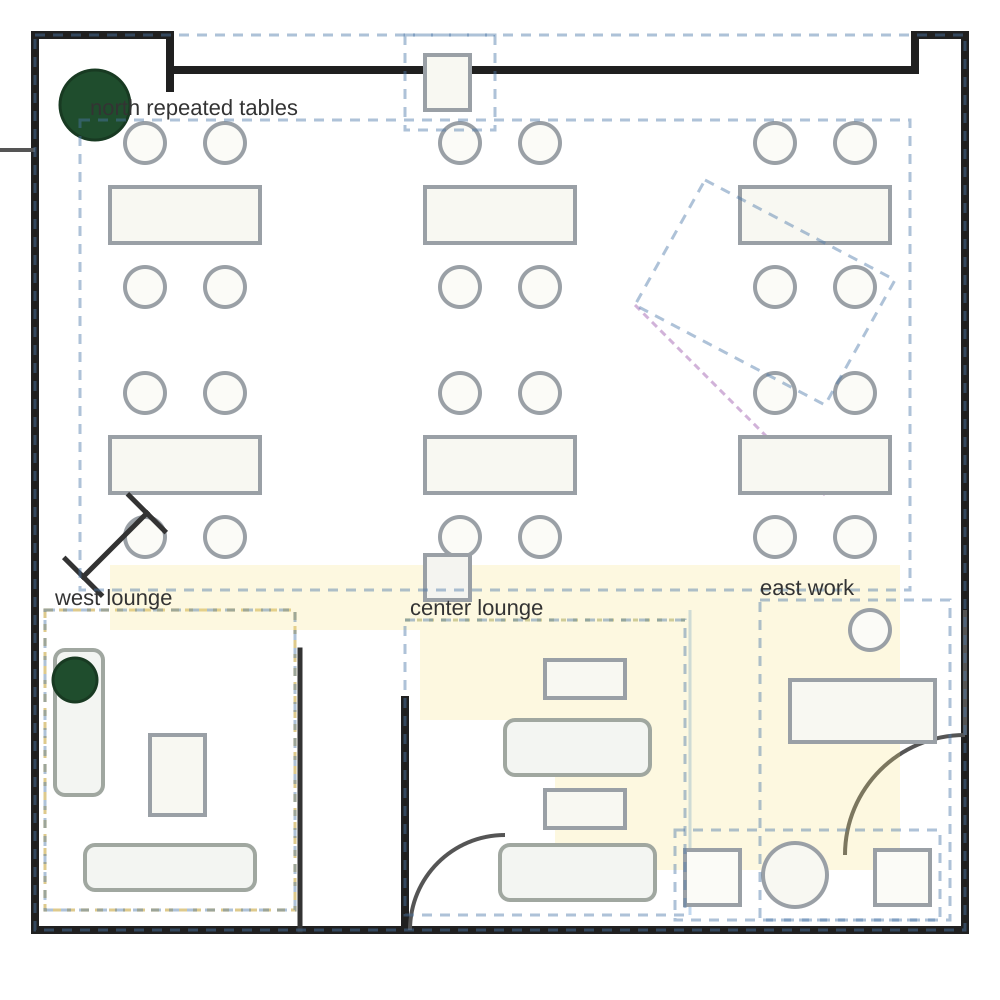

In [1]:
from pathlib import Path
from IPython.display import SVG, display

fixture_path = Path('test/floorplan_order_fixture.svg')
display(SVG(filename=str(fixture_path)))

In [2]:
from features import load_structured_svg_scene, evaluate_scene, scene_metric_overlay_svg

scene = load_structured_svg_scene(fixture_path)
matrix = evaluate_scene(scene)
sampled = matrix['sampled_walkable_space']

print('objects:', len(scene['objects']))
print('groups:', sorted({obj['group'] for obj in scene['objects']}))
print('metric rows:', len(matrix['rows']))
print('sampled walkable ratio:', sampled['walkable_cell_ratio'])
print('sampled entry reachable ratio:', sampled['entry_reachable_cell_ratio'])
print('adapter payload records:', matrix['adapter_payload']['record_count'])

objects: 22
groups: ['center_lounge', 'east_armchairs', 'east_work', 'misc', 'north_tables', 'north_wall', 'west_lounge']
metric rows: 144
sampled walkable ratio: 0.8912
sampled entry reachable ratio: 0.8912
adapter payload records: 46


In [3]:
try:
    import pandas as pd
    display(pd.DataFrame(matrix['rows']))
except Exception:
    matrix['rows']

,view_id,metric,score,status,method,evidence,uncertainty,axis_evidence,region_centroid_phase_evidence,region_axis_evidence,...,entry_positions,entry_boundary_associations,boundary_opening_evidence,boundary_path_opening_evidence,weight_metadata_evidence,missing_weight_metadata_ids,adapter_reference_evidence,adapter_reference_role_coverage,record_count,route_evidence
0,north_tables_order,octa_table_pattern,1.0000,computed,octa_shapes_custom_attr,"[north_table_r1_c1, north_table_r1_c2, north_t...",valid only for comparable repeated table objects,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,north_tables_order,x_phase_regular,1.0000,computed,gap_cv_score,"[north_table_r1_c1, north_table_r1_c2, north_t...",checks first repeated table row spacing,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,west_lounge_geometry,compactness,0.4321,computed,occupied_area_over_bbox_area,"[west_sofa_1, west_sofa_2, west_coffee_table, ...","compactness is descriptive, not automatically ...",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,center_lounge_geometry,compactness,0.6070,computed,occupied_area_over_bbox_area,"[center_sofa_upper, center_coffee_table_upper,...","compactness is descriptive, not automatically ...",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,east_armchair_geometry,compactness,0.6471,computed,occupied_area_over_bbox_area,"[east_armchair_left, east_coffee_table, east_a...","compactness is descriptive, not automatically ...",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,boundary_metrics,glass_walk_see_gap,0.8500,computed,walk_block_minus_see_block_for_glass,[glass_boundary],authored glass transparency weight; material/l...,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,boundary_metrics,rug_grouping_without_block,0.8500,computed,rug_grouping_strength_without_walk_or_see_block,[rug_boundary],authored surface-cue weight; perception calibr...,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
141,adapter_readiness,adapter_reference_coverage,0.0435,computed,records_with_external_adapter_refs_over_scene_...,"[north_table_r1_c1, room_boundary]",adapter refs are traceability metadata only; t...,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"[{'id': 'north_table_r1_c1', 'role': 'table', ...","{'armchair': {'record_count': 2, 'referenced_c...",46.0,NaN
142,uncertainties,open_items,0.0000,computed,uncertainty_log,[],perceptual assumptions remain explicit,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


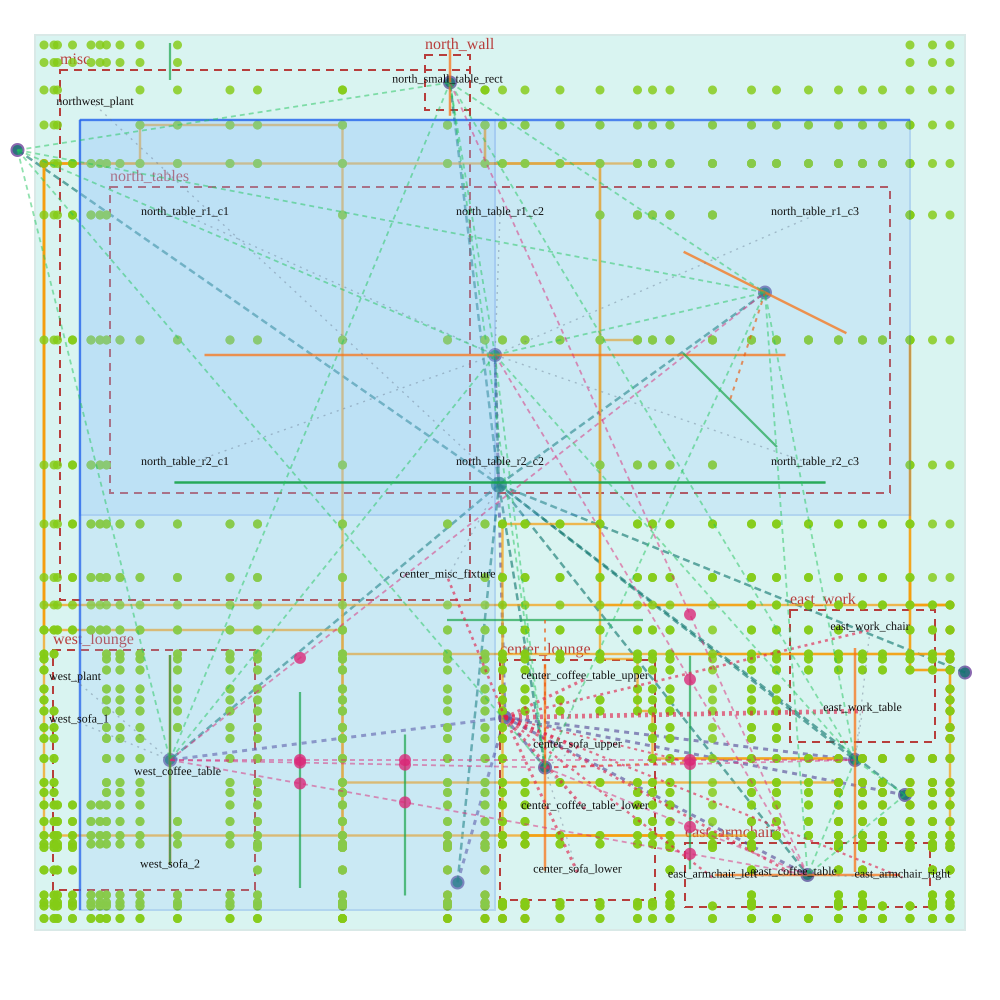

In [4]:
display(SVG(data=scene_metric_overlay_svg(scene, matrix)))

In [5]:
path_rows = {row['metric']: row for row in matrix['rows'] if row['view_id'] == 'path_connectivity'}
boundary_rows = {row['metric']: row for row in matrix['rows'] if row['view_id'] == 'boundary_metrics'}
column_rows = {row['metric']: row for row in matrix['rows'] if row['view_id'] == 'column_alignment'}
adapter_rows = {row['metric']: row for row in matrix['rows'] if row['view_id'] == 'adapter_readiness'}
uncertainty_rows = {row['metric']: row for row in matrix['rows'] if row['view_id'] == 'uncertainties'}
audit = {
    'automatic_loader': True,
    'manual_fixture_object_table': False,
    'overlay_layers': [
        'free-space-graph-entry-region-path',
        'free-space-graph-entry-anchor',
        'free-space-graph-region-anchor',
    ],
    'required_views': sorted({row['view_id'] for row in matrix['rows']}),
    'path_connectivity_scores': {
        'line_of_sight_entry_region_ratio': path_rows['line_of_sight_entry_region_ratio']['score'],
        'line_of_sight_region_pair_ratio': path_rows['line_of_sight_region_pair_ratio']['score'],
        'graph_entry_region_capacity_proxy': path_rows['graph_entry_region_capacity_proxy']['score'],
        'graph_dead_end_ratio': path_rows['graph_dead_end_ratio']['score'],
        'graph_loop_ratio': path_rows['graph_loop_ratio']['score'],
        'disconnected_entry_ratio': path_rows['disconnected_entry_ratio']['score'],
        'disconnected_path_ratio': path_rows['disconnected_path_ratio']['score'],
        'sampled_visibility_reachable_region_ratio': path_rows['sampled_visibility_reachable_region_ratio']['score'],
        'sampled_entry_reachable_region_pair_ratio': path_rows['sampled_entry_reachable_region_pair_ratio']['score'],
        'sampled_visibility_reachable_region_pair_ratio': path_rows['sampled_visibility_reachable_region_pair_ratio']['score'],
        'sampled_walk_visibility_disagreement_region_pair_ratio': path_rows['sampled_walk_visibility_disagreement_region_pair_ratio']['score'],
        'sampled_mean_region_pair_grid_distance': path_rows['sampled_mean_region_pair_grid_distance']['score'],
        'sampled_region_pair_reachable_ratio': path_rows['sampled_region_pair_reachable_ratio']['score'],
        'sampled_resolution_sensitivity': path_rows['sampled_resolution_sensitivity']['score'],
        'isovist_radial_blocked_ray_ratio': path_rows['isovist_radial_blocked_ray_ratio']['score'],
        'isovist_radial_hit_polygon_area_mean': path_rows['isovist_radial_hit_polygon_area_mean']['score'],
        'negative_space_non_entry_connected_area_ratio': path_rows['negative_space_non_entry_connected_area_ratio']['score'],
        'negative_space_component_area_residual_ratio': path_rows['negative_space_component_area_residual_ratio']['score'],
        'negative_space_component_cell_area_residual_ratio': path_rows['negative_space_component_cell_area_residual_ratio']['score'],
        'candidate_path_area_ratio_proxy': path_rows['candidate_path_area_ratio_proxy']['score'],
        'candidate_path_region_pair_ratio_proxy': path_rows['candidate_path_region_pair_ratio_proxy']['score'],
        'negative_space_entry_connected_region_area_coverage_ratio': path_rows['negative_space_entry_connected_region_area_coverage_ratio']['score'],
    },
    'negative_space_component_closure': {
        'component_area_total': matrix['negative_space']['component_area_total'],
        'component_cell_count_total': matrix['negative_space']['component_cell_count_total'],
        'free_space_polygon_count': path_rows['negative_space_free_polygon_count']['score'],
        'room_minus_blocker_polygon_count': path_rows['negative_space_room_minus_blocker_polygon_count']['score'],
        'cad_room_minus_blocker_polygon_count': path_rows['cad_room_minus_blocker_polygon_count']['score'],
        'cad_room_minus_blocker_largest_component_area_ratio': path_rows['cad_room_minus_blocker_largest_component_area_ratio']['score'],
        'cad_room_minus_blocker_entry_connected_region_ratio': path_rows['cad_room_minus_blocker_entry_connected_region_ratio']['score'],
        'cad_room_minus_blocker_entry_connected_area_ratio': path_rows['cad_room_minus_blocker_entry_connected_area_ratio']['score'],
        'cad_room_minus_blocker_entry_connected_component_ratio': path_rows['cad_room_minus_blocker_entry_connected_component_ratio']['score'],
        'cad_room_minus_blocker_entry_connected_region_pair_ratio': path_rows['cad_room_minus_blocker_entry_connected_region_pair_ratio']['score'],
        'cad_room_minus_blocker_component_graph_edge_count': path_rows['cad_room_minus_blocker_component_graph_edge_count']['score'],
        'free_space_polygon_adjacency_count': path_rows['negative_space_free_polygon_adjacency_count']['score'],
        'free_space_polygon_graph_cycle_rank': path_rows['free_space_polygon_graph_cycle_rank']['score'],
        'free_space_polygon_graph_mean_entry_region_distance': path_rows['free_space_polygon_graph_mean_entry_region_distance']['score'],
        'free_space_polygon_graph_mean_edge_clearance_width': path_rows['free_space_polygon_graph_mean_edge_clearance_width']['score'],
        'free_space_polygon_graph_mean_entry_region_min_clearance_width': path_rows['free_space_polygon_graph_mean_entry_region_min_clearance_width']['score'],
        'free_space_polygon_graph_mean_entry_region_widest_clearance_width': path_rows['free_space_polygon_graph_mean_entry_region_widest_clearance_width']['score'],
        'mean_entry_region_free_polygon_distance': path_rows['negative_space_mean_entry_region_free_polygon_distance']['score'],
        'mean_entry_region_free_polygon_path_length': path_rows['negative_space_mean_entry_region_free_polygon_path_length']['score'],
        'component_cell_area_sum_total': matrix['negative_space']['component_cell_area_sum_total'],
        'negative_space_component_area_residual': matrix['negative_space']['negative_space_component_area_residual'],
        'negative_space_component_area_residual_ratio': matrix['negative_space']['negative_space_component_area_residual_ratio'],
        'cad_room_minus_blocker_area_total': matrix['negative_space']['cad_room_minus_blocker_area_total'],
        'cad_room_minus_blocker_area_residual': matrix['negative_space']['cad_room_minus_blocker_area_residual'],
        'cad_room_minus_blocker_area_residual_ratio': path_rows['cad_room_minus_blocker_area_residual_ratio']['score'],
        'room_minus_blocker_polygons': matrix['negative_space']['room_minus_blocker_polygons'],
        'cad_room_minus_blocker_polygons': matrix['negative_space']['cad_room_minus_blocker_polygons'],
        'cad_room_minus_blocker_component_touch_evidence': matrix['negative_space']['cad_room_minus_blocker_component_touch_evidence'],
    },
    'negative_space_graph_metrics': {
        'entry_connected_component_ids': matrix['negative_space_graph']['metrics']['entry_connected_component_ids'],
        'non_entry_connected_component_ids': matrix['negative_space_graph']['metrics']['non_entry_connected_component_ids'],
        'entry_connected_component_area': matrix['negative_space_graph']['metrics']['entry_connected_component_area'],
        'non_entry_connected_component_area': matrix['negative_space_graph']['metrics']['non_entry_connected_component_area'],
        'entry_connected_area_ratio': matrix['negative_space_graph']['metrics']['entry_connected_area_ratio'],
        'non_entry_connected_area_ratio': matrix['negative_space_graph']['metrics']['non_entry_connected_area_ratio'],
        'entry_connected_region_pair_count': matrix['negative_space_graph']['metrics']['entry_connected_region_pair_count'],
        'total_region_pair_count': matrix['negative_space_graph']['metrics']['total_region_pair_count'],
        'entry_connected_region_pair_ratio': matrix['negative_space_graph']['metrics']['entry_connected_region_pair_ratio'],
        'entry_connected_region_pair_evidence': matrix['negative_space_graph']['metrics']['entry_connected_region_pair_evidence'],
        'unconnected_region_pair_evidence': matrix['negative_space_graph']['metrics']['unconnected_region_pair_evidence'],
        'component_cell_counts': matrix['negative_space_graph']['metrics']['component_cell_counts'],
        'component_cell_area_sums': matrix['negative_space_graph']['metrics']['component_cell_area_sums'],
        'component_cell_area_residuals': matrix['negative_space_graph']['metrics']['component_cell_area_residuals'],
        'max_component_cell_area_residual_ratio': matrix['negative_space_graph']['metrics']['max_component_cell_area_residual_ratio'],
        'entry_region_free_polygon_distance_evidence': matrix['negative_space_graph']['metrics']['entry_region_free_polygon_distance_evidence'],
    },
    'isovist_radial_proxy': {
        'vantage_count': matrix['isovist_radial_proxy']['metrics']['vantage_count'],
        'ray_count': matrix['isovist_radial_proxy']['metrics']['ray_count'],
        'blocked_ray_count': matrix['isovist_radial_proxy']['metrics']['blocked_ray_count'],
        'blocked_ray_ratio': matrix['isovist_radial_proxy']['metrics']['blocked_ray_ratio'],
        'mean_hit_distance': matrix['isovist_radial_proxy']['metrics']['mean_hit_distance'],
        'mean_hit_polygon_area': matrix['isovist_radial_proxy']['metrics']['mean_hit_polygon_area'],
        'isovist_area_evidence': matrix['isovist_radial_proxy']['isovist_area_evidence'],
    },
    'column_alignment_scores': {
        'object_column_axis_phase_alignment': column_rows['object_column_axis_phase_alignment']['score'],
        'region_column_bay_fit': column_rows['region_column_bay_fit']['score'],
        'object_column_bay_local_position_coverage': column_rows['object_column_bay_local_position_coverage']['score'],
        'object_bay_local_position_evidence_count': len(column_rows['object_column_bay_local_position_coverage']['object_bay_local_position_evidence']),
    },
    'boundary_scores': {
        'closed_blocking_boundary_ratio': boundary_rows['closed_blocking_boundary_ratio']['score'],
        'fallback_entry_boundary_ratio': boundary_rows['fallback_entry_boundary_ratio']['score'],
        'boundary_weight_metadata_coverage': boundary_rows['boundary_weight_metadata_coverage']['score'],
        'missing_weight_metadata_ids': boundary_rows['boundary_weight_metadata_coverage']['missing_weight_metadata_ids'],
        'glass_walk_see_gap': boundary_rows['glass_walk_see_gap']['score'],
        'rug_grouping_without_block': boundary_rows['rug_grouping_without_block']['score'],
    },
    'boundary_opening_audit': {
        item['id']: item['path_disconnected_opening_ids']
        for item in boundary_rows['boundary_path_connected_opening_ratio_max']['boundary_path_opening_evidence']
    },
    'adapter_readiness': {
        'adapter_reference_coverage': adapter_rows['adapter_reference_coverage']['score'],
        'adapter_reference_evidence': adapter_rows['adapter_reference_coverage']['adapter_reference_evidence'],
        'adapter_reference_role_coverage': adapter_rows['adapter_reference_coverage']['adapter_reference_role_coverage'],
    },
    'adapter_payload': {
        'record_count': matrix['adapter_payload']['record_count'],
        'scene_records': matrix['adapter_payload']['scene_records'][:4],
        'external_refs': matrix['adapter_payload']['external_refs'],
        'evidence_geometry': {
            'free_space_polygon_count': matrix['adapter_payload']['evidence_geometry']['free_space_polygons']['count'],
            'free_space_polygon_preview': matrix['adapter_payload']['evidence_geometry']['free_space_polygons']['items'],
            'free_space_polygon_graph_node_count': matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['node_count'],
            'free_space_polygon_graph_edge_count': matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['edge_count'],
            'free_space_polygon_graph_cycle_rank': matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['metrics']['cycle_rank'],
            'free_space_polygon_graph_mean_edge_clearance_width': path_rows['free_space_polygon_graph_mean_edge_clearance_width']['score'],
            'free_space_polygon_graph_mean_entry_region_min_clearance_width': path_rows['free_space_polygon_graph_mean_entry_region_min_clearance_width']['score'],
            'free_space_polygon_graph_mean_entry_region_widest_clearance_width': path_rows['free_space_polygon_graph_mean_entry_region_widest_clearance_width']['score'],
            'free_space_polygon_graph_dead_end_node_count': matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['metrics']['dead_end_node_count'],
            'free_space_polygon_graph_entry_anchor_count': len(matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['anchors']['entries']),
            'free_space_polygon_graph_region_anchor_count': len(matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['anchors']['regions']),
            'free_space_polygon_graph_entry_region_distance_count': len(matrix['adapter_payload']['evidence_geometry']['free_space_polygon_graph']['entry_region_distance_evidence']),
            'room_minus_blocker_polygon_count': matrix['adapter_payload']['evidence_geometry']['room_minus_blocker_polygons']['count'],
            'cad_room_minus_blocker_polygon_count': matrix['adapter_payload']['evidence_geometry']['cad_room_minus_blocker_polygons']['count'],
            'cad_room_minus_blocker_entry_connected_area_ratio': matrix['adapter_payload']['evidence_geometry']['cad_room_minus_blocker_entry_connected_area']['entry_connected_area_ratio'],
            'cad_room_minus_blocker_component_touch_count': len(matrix['adapter_payload']['evidence_geometry']['cad_room_minus_blocker_component_touch_evidence']['items']),
            'cad_room_minus_blocker_component_graph_node_count': matrix['adapter_payload']['evidence_geometry']['cad_room_minus_blocker_component_graph']['node_count'],
            'cad_room_minus_blocker_component_graph_edge_count': matrix['adapter_payload']['evidence_geometry']['cad_room_minus_blocker_component_graph']['edge_count'],
            'negative_space_graph_node_count': matrix['adapter_payload']['evidence_geometry']['negative_space_graph']['node_count'],
            'negative_space_graph_edge_count': matrix['adapter_payload']['evidence_geometry']['negative_space_graph']['edge_count'],
        },
        'metric_row_count': len(matrix['adapter_payload']['metric_rows']),
    },
    'uncertainty_routes': uncertainty_rows['uncertainty_routes']['evidence'],
    'sampled_walkable_space': matrix['sampled_walkable_space'],
}
audit

{'automatic_loader': True,
 'manual_fixture_object_table': False,
 'overlay_layers': ['free-space-graph-entry-region-path',
  'free-space-graph-entry-anchor',
  'free-space-graph-region-anchor'],
 'required_views': ['adapter_readiness',
  'boundary_connectivity',
  'boundary_metrics',
  'center_lounge_geometry',
  'column_alignment',
  'east_armchair_geometry',
  'north_tables_order',
  'path_connectivity',
  'region_alignment',
  'uncertainties',
  'west_lounge_geometry',
  'whole_space_force'],
 'path_connectivity_scores': {'line_of_sight_entry_region_ratio': 1.0,
  'line_of_sight_region_pair_ratio': 0.619,
  'graph_entry_region_capacity_proxy': 0.2386,
  'graph_dead_end_ratio': 0.9167,
  'graph_loop_ratio': 0.0,
  'disconnected_entry_ratio': 0.5,
  'disconnected_path_ratio': 0.0,
  'sampled_visibility_reachable_region_ratio': 1.0,
  'sampled_entry_reachable_region_pair_ratio': 1.0,
  'sampled_visibility_reachable_region_pair_ratio': 1.0,
  'sampled_walk_visibility_disagreement_regio